# 06 - SHAP Explainability

**Goal:** open up the final model: *which features drive its risk scores, in which direction, and why does it score a particular customer the way it does?*

## SHAP in plain language
* A prediction can be written as: `model output = base value + sum of each feature's contribution`. SHAP values are those contributions.
* They come from **Shapley values** (cooperative game theory): a feature's contribution is its *average marginal effect* on the prediction over all possible orders in which features could be "added", so credit is shared fairly. For tree models, `TreeExplainer` computes this exactly and efficiently.
* For our LightGBM model the output is in **log-odds**: positive SHAP = pushes churn risk up, negative = pushes it down. `base value` is the average model output on the training background.
* **Global interpretability** = what matters on average across customers (mean |SHAP|, beeswarm). **Local interpretability** = why *this* customer got *this* score (waterfall plot).

## Important warnings
1. **SHAP explains the model, not the world.** A large SHAP value means "the model relies on this feature", i.e. a predictive *association*. It does **not** say that changing the feature would change churn.
2. Correlated features share credit unpredictably (e.g. `tenure` / `TotalCharges` / `MonthlyCharges`; one-hot dummies of the same variable).
3. SHAP values describe *this* model, trained on *this* sample.

We compute SHAP on the **held-out test customers** (unseen data), using a 500-customer training sample as background. We first verify the explainer is correct.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets notebooks import the src/ package

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    """Save the current figure into reports/figures (used by README and dashboard)."""
    plt.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
import json, joblib
from src.data_preprocessing import load_split, split_xy
from src.explain import (load_model_parts, compute_shap, importance_tables, plot_summary, plot_importance_bar, plot_waterfall, pick_local_examples)
pipe, pre, clf = load_model_parts()
meta = json.loads(config.METADATA_PATH.read_text()); print("Model:", type(clf).__name__, "| explainer: shap.TreeExplainer")
Xtr, ytr = split_xy(load_split("train")); test_df = load_split("test"); Xte, yte = split_xy(test_df)
expl, Xt, units = compute_shap(pipe, Xte, Xtr.sample(500, random_state=config.RANDOM_STATE))
# Correctness check: base value + sum of SHAP values must reproduce the model's raw output
raw = clf.predict(Xt.values, raw_score=True)
print(f"units = {units}; max |(base + sum SHAP) - model log-odds| = {np.max(np.abs(expl.base_values + expl.values.sum(1) - raw)):.2e}")

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: LGBMClassifier | explainer: shap.TreeExplainer
units = log-odds; max |(base + sum SHAP) - model log-odds| = 6.22e-15


The reconstruction error is at floating-point level, so SHAP values add up exactly to the model's output: the explainer is correctly matched to the model and library versions.

## A. Global explanations

,feature,mean_abs_shap
0,Contract,0.724
1,tenure,0.347
2,InternetService,0.303
3,OnlineSecurity,0.249
4,TotalCharges,0.173
5,MonthlyCharges,0.165
6,PaymentMethod,0.158
7,TechSupport,0.141
8,PaperlessBilling,0.123
9,MultipleLines,0.098


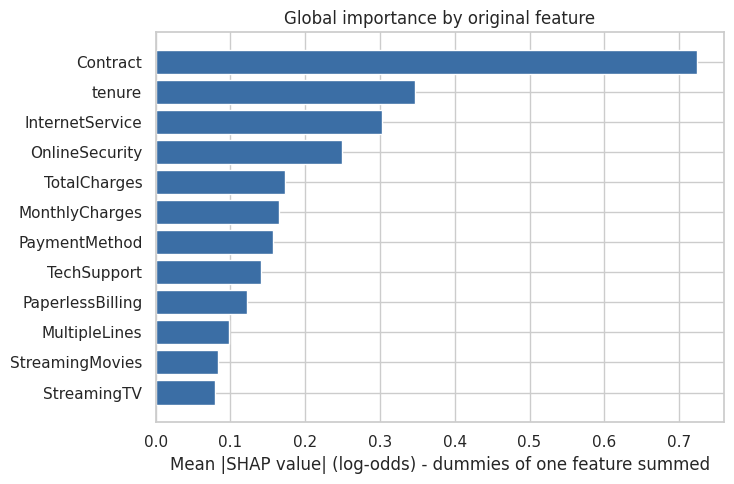

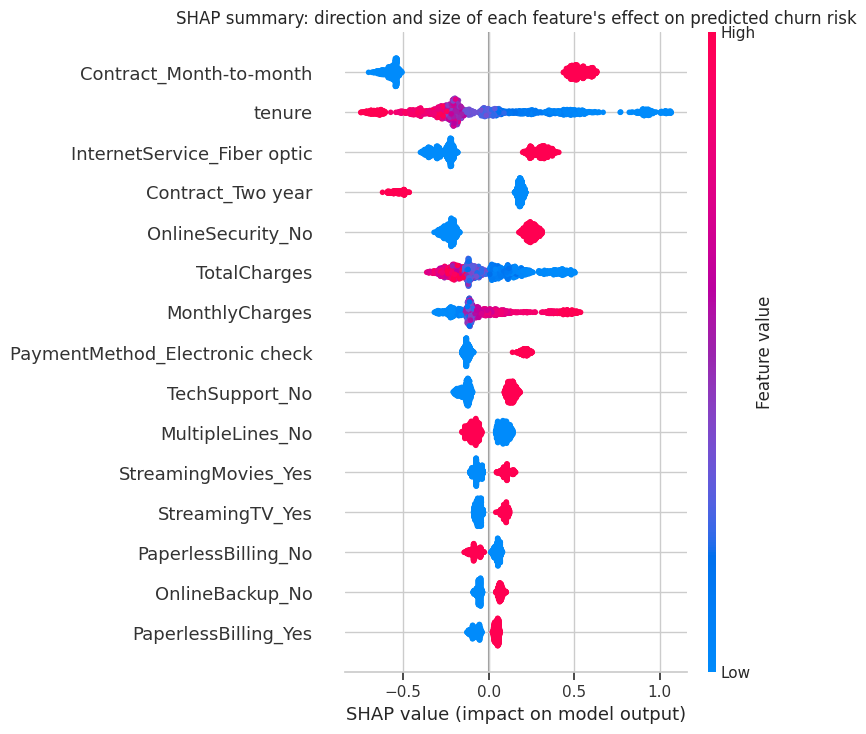

In [3]:
per_col, per_feature = importance_tables(expl, config.CATEGORICAL_FEATURES)
display(per_feature.head(12).round(3))
plot_importance_bar(per_feature, units); plt.show()
plot_summary(expl, Xt); plt.show()

**Reading the global importance (actual output).**
* **Contract** is by far the most influential feature (mean |SHAP| 0.72 log-odds, about twice the next), then **tenure** (0.35), **InternetService** (0.30), **OnlineSecurity** (0.25), then `TotalCharges`, `MonthlyCharges`, `PaymentMethod`, `TechSupport`, `PaperlessBilling`. These match the EDA ranking (Cramer's V / Cliff's delta) - a useful sanity check that the model learned the same broad story as the descriptive analysis.
* **Direction (beeswarm):** month-to-month contracts, fiber-optic internet, no online security / tech support, electronic-check payment and *short* tenure all push predicted risk **up**; two-year contracts and *long* tenure push it **down** (red = high feature value; for tenure the red dots sit on the negative side).
* **MonthlyCharges** shows higher charges mostly pushing risk up *after accounting for the other features*. This differs from the within-service-type pattern in the EDA (where higher bills went with lower churn). Both can hold: conditional on the other columns, an unusually high bill reflects pricing rather than extra services. This is a reminder that SHAP direction depends on which other features are in the model - so we should not turn it into pricing advice.
* `gender` does not appear among the top features, consistent with EDA showing no association.

### Does the conclusion depend on the model? A robustness check
If a very different model (a linear one) tells the same story, we can trust the pattern more. We fit a Logistic Regression on the same development data (not for prediction, only for this comparison) and compare feature rankings.

In [4]:
from sklearn.linear_model import LogisticRegression
from src.data_preprocessing import make_pipeline
import shap
lr = make_pipeline(LogisticRegression(max_iter=3000), "base", True).fit(Xtr, ytr)
Xt_lr = pd.DataFrame(lr[:-1].transform(Xte), columns=[n.split("__", 1)[1] for n in lr.named_steps["preprocess"].get_feature_names_out()])
Xb_lr = pd.DataFrame(lr[:-1].transform(Xtr.sample(100, random_state=0)), columns=Xt_lr.columns)
lr_vals = shap.LinearExplainer(lr.named_steps["model"], Xb_lr).shap_values(Xt_lr)
e_lr = shap.Explanation(values=lr_vals, base_values=np.zeros(len(Xt_lr)), data=Xt_lr.values, feature_names=list(Xt_lr.columns))
_, pf_lr = importance_tables(e_lr, config.CATEGORICAL_FEATURES)
cmp = per_feature.merge(pf_lr, on="feature", suffixes=("_lightgbm", "_logreg"))
cmp["rank_lightgbm"] = cmp["mean_abs_shap_lightgbm"].rank(ascending=False); cmp["rank_logreg"] = cmp["mean_abs_shap_logreg"].rank(ascending=False)
from scipy.stats import spearmanr
print("Spearman rank correlation of feature importance (LightGBM vs LogReg):", round(spearmanr(cmp.rank_lightgbm, cmp.rank_logreg)[0], 3))
display(cmp.sort_values("rank_lightgbm").head(10)[["feature", "rank_lightgbm", "rank_logreg"]])

Spearman rank correlation of feature importance (LightGBM vs LogReg): 0.877


,feature,rank_lightgbm,rank_logreg
0,Contract,1.0,3.0
1,tenure,2.0,1.0
2,InternetService,3.0,2.0
3,OnlineSecurity,4.0,8.0
4,TotalCharges,5.0,5.0
5,MonthlyCharges,6.0,4.0
6,PaymentMethod,7.0,12.0
7,TechSupport,8.0,11.0
8,PaperlessBilling,9.0,10.0
9,MultipleLines,10.0,9.0


The two models agree broadly (Spearman rank correlation 0.87): tenure, InternetService, TotalCharges, MonthlyCharges and Contract are in the top six for both, and the same weak features sit at the bottom. They disagree on details: **Contract is #1 for LightGBM but only #4 for Logistic Regression**, while the linear model ranks MonthlyCharges #3. Correlated features (price, services, tenure, total charges) can trade credit between them, so exact ranks should not be over-interpreted - the broad story (contract, tenure, internet service and add-ons matter most) is the robust part.

### Dependence on tenure

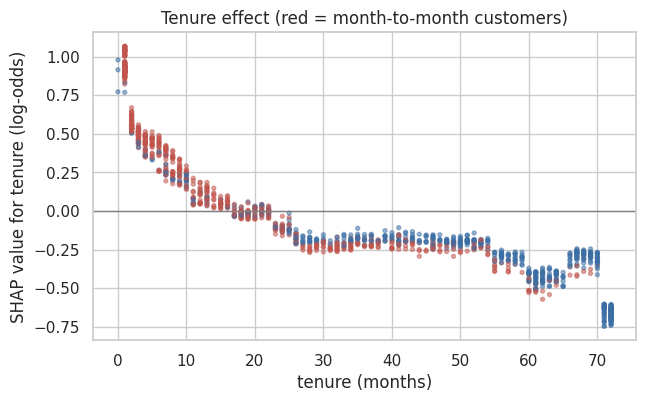

In [5]:
i = list(Xt.columns).index("tenure")
plt.figure(figsize=(7, 4))
plt.scatter(Xt["tenure"], expl.values[:, i], s=8, alpha=0.5, c=(Xte["Contract"] == "Month-to-month").map({True: "#c1554d", False: "#3b6ea5"}))
plt.axhline(0, c="grey", lw=1); plt.xlabel("tenure (months)"); plt.ylabel("SHAP value for tenure (log-odds)")
plt.title("Tenure effect (red = month-to-month customers)"); savefig("shap_dependence_tenure.png"); plt.show()

The effect of tenure is strongly non-linear: customers in their first months get contributions of up to about +1.0 log-odds, which fall steadily to roughly zero around month 20, then settle on a plateau near -0.2 for months ~27-54, with further step-downs near month 60 and at 71-72. The early steep decline is the real pattern (matching the EDA churn-by-tenure bands); the later steps are probably partly an artefact of tree splits in sparse regions and should not be over-read. A single linear term would miss this shape, which is why `tenure_group` was a natural feature to test in notebook 03.

## B. Local explanations - five real test customers
Selected automatically: the highest-risk customer, the lowest-risk, one right at the decision threshold, a **missed churner** (false negative) and a **false alarm** (false positive). The last two are the most instructive: they show where the model is wrong.

,example,customerID,predicted_probability,actual_churn,tenure,Contract,InternetService,OnlineSecurity,TechSupport,PaymentMethod,MonthlyCharges
0,highest_risk,5178-LMXOP,0.905,1,1,Month-to-month,Fiber optic,No,No,Electronic check,95.10
1,lowest_risk,4277-BWBML,0.009,0,72,Two year,No,No internet service,No internet service,Bank transfer (automatic),19.95
2,near_threshold,2087-QAREY,0.220,0,22,Month-to-month,DSL,No,No,Mailed check,54.70
3,missed_churner_FN,2165-VOEGB,0.136,1,46,One year,Fiber optic,Yes,Yes,Bank transfer (automatic),105.20
4,false_alarm_FP,2545-EBUPK,0.842,0,2,Month-to-month,Fiber optic,No,No,Electronic check,84.05


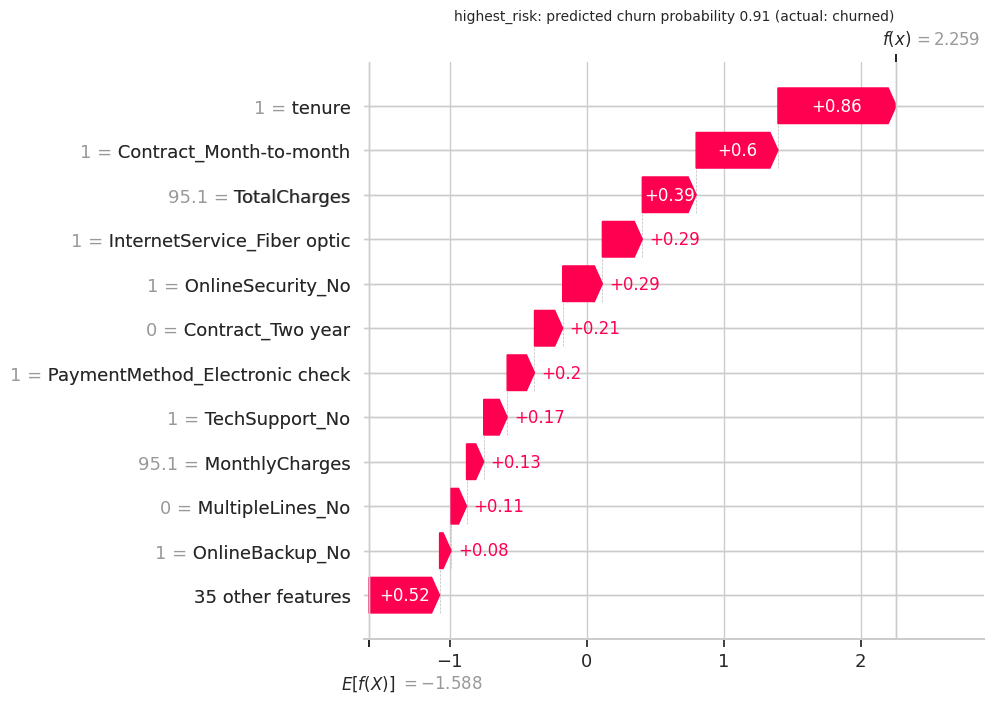

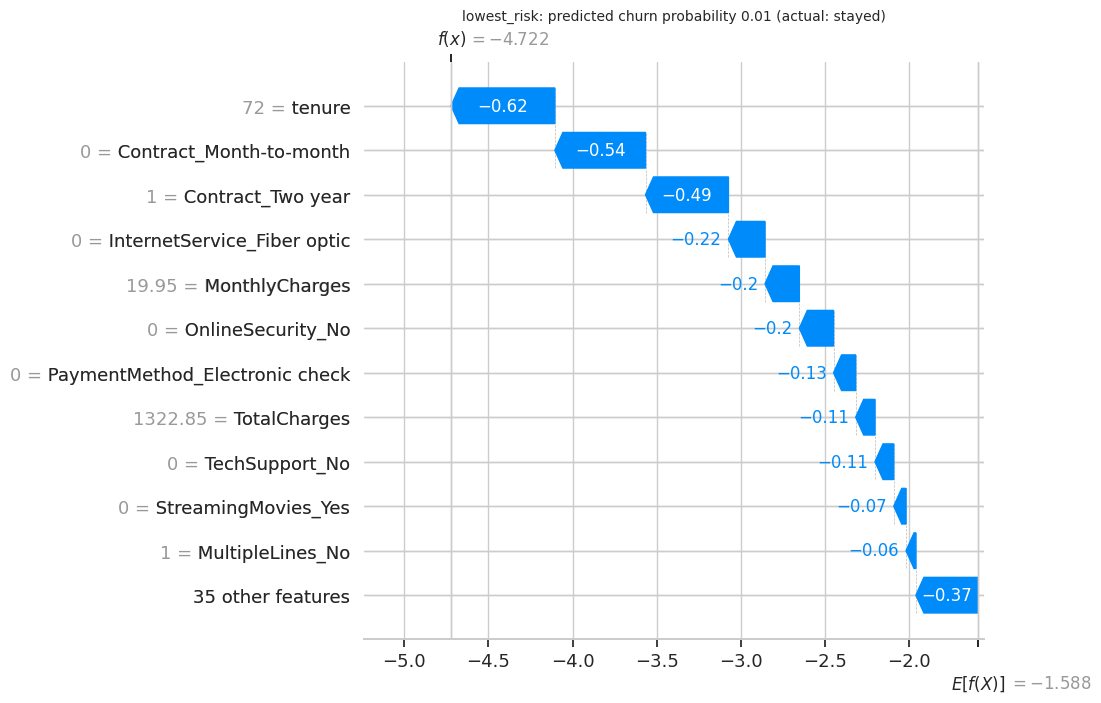

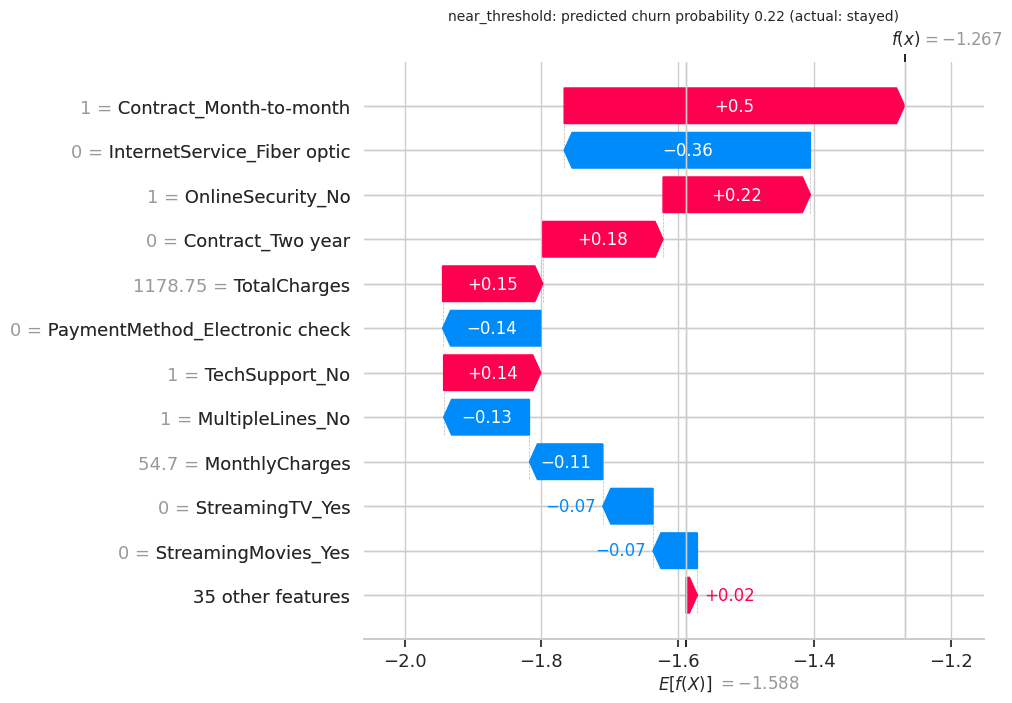

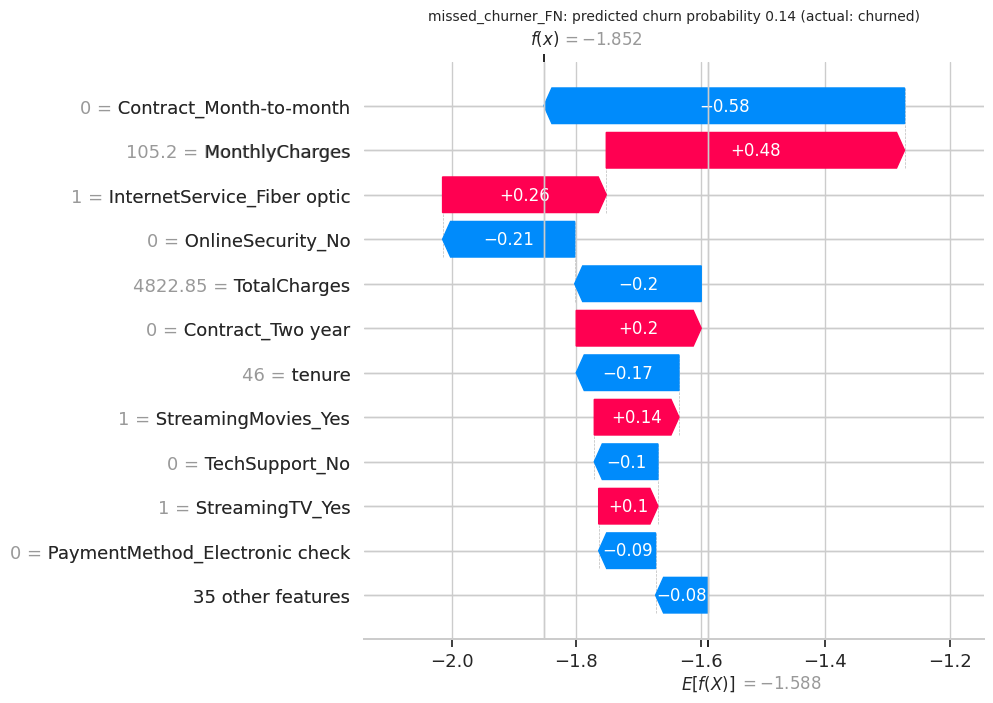

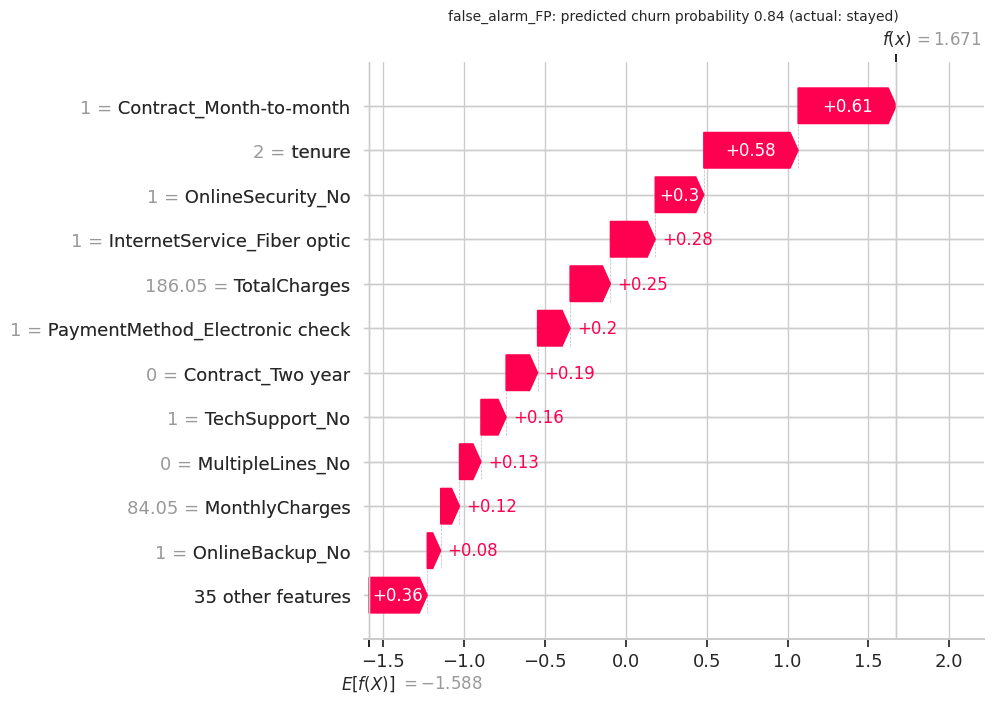

In [6]:
ex = pd.read_csv(config.REPORTS_DIR / "shap_local_examples.csv")
display(ex[["example", "customerID", "predicted_probability", "actual_churn", "tenure", "Contract", "InternetService", "OnlineSecurity", "TechSupport", "PaymentMethod", "MonthlyCharges"]].round(3))
prob = pipe.predict_proba(Xte)[:, 1]; picks = pick_local_examples(yte, prob, meta["threshold"])
for kind, i in picks.items():
    plot_waterfall(expl, i, f"{kind}: predicted churn probability {prob[i]:.2f} (actual: {'churned' if yte[i] else 'stayed'})", f"shap_waterfall_{kind}.png"); plt.show()

**How to read a waterfall:** start at `E[f(X)]` (the average model output, in log-odds), each bar adds or subtracts a feature's contribution, and the final value `f(x)` converts to the probability shown in the title.

**What the five examples show (see the plots above):**
* *Highest risk:* a month-to-month, short-tenure, fiber-optic customer with no security/support add-ons and electronic-check payment - almost every feature pushes risk up. The model is confident, and this customer did churn.
* *Lowest risk:* long tenure, a long contract and low risk factors; the model gives <1% and the customer stayed.
* *Near the threshold (p = 0.22, stayed):* contributions largely offset each other. Being on a month-to-month contract (+0.50 log-odds), having no OnlineSecurity (+0.22) and no TechSupport (+0.14) push risk up, while being on DSL rather than fiber (-0.36), paying by mailed check rather than electronic check (-0.14) and a modest bill push it down. This is exactly where a small change flips the decision, so such borderline customers should not be labelled "high risk".
* *Missed churner (FN, p = 0.14, churned):* a customer with a one-year contract (month-to-month = 0 contributes -0.58), 46 months of tenure (-0.17), and security and support add-ons (-0.21, -0.10). Fiber optic (+0.26) and a high bill of $105 (+0.48) push the other way but not enough. Nothing in the recorded features marks this customer as likely to leave, so the reason they left is probably *not in the dataset* (a competitor offer, a service problem...). SHAP cannot explain what the model never saw.
* *False alarm (FP):* a customer scored about 0.84 who stayed: their profile matches high-churn patterns, but they did not leave - a reminder that a probability is a model estimate, not a verdict.

## C. Interpretation limits (read before using SHAP in a presentation)
* **Predictive association, not causation.** "Month-to-month contract raises predicted risk" does not mean forcing a customer onto a 2-year contract lowers their churn - committed customers may select long contracts.
* **Feature importance != actionable lever.** `tenure` is the second most important feature and cannot be "changed" at all; `MonthlyCharges` direction can invert depending on which other features are present.
* **Instability with correlated features.** Credit may be split differently if features are removed or the model is retrained. Use SHAP to generate hypotheses, then validate with experiments.

## What to remember / interview questions
* *"How are SHAP values computed?"* - Average marginal contribution of a feature over feature coalitions (Shapley values); TreeExplainer uses the tree structure to do this exactly in polynomial time.
* *"Global vs local explanations?"* - Global: average behaviour (importance, beeswarm). Local: one prediction (waterfall).
* *"SHAP vs permutation importance vs coefficients?"* - SHAP gives signed, per-customer attributions; permutation importance measures loss in score when a feature is shuffled; coefficients are specific to linear models and depend on scaling.
* *"Can SHAP tell us how to reduce churn?"* - No; it describes the model. Causal questions need experiments or causal inference.